# 03 · Dense NN, vanilla RNN, LSTM y BiLSTM (extra) — Sentiment analysis (GoEmotions)
**Responsable:** Camila · Usa el split ya generado (`data/processed/train.csv` y `test.csv`, 800/200).
El test **solo** se usa para la evaluación final; el tuning se hace con validación cruzada dentro de train.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.train import (load_tokens, grid_search, final_runs, ALL_MODEL_NAMES, GRID, FIXED, log, SEED)
from src.evaluate import METRICS_DIR

FIG_DIR = ROOT / "outputs" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
QUICK = False   # True = grid reducido para probar que todo corre (unos minutos menos)

## 1. Datos

In [2]:
tok_tr, y_tr, tok_te, y_te = load_tokens("clean")
lens = [len(t) for t in tok_tr]
print(f"train={len(tok_tr)} test={len(tok_te)} | balance train={np.bincount(y_tr)} test={np.bincount(y_te)}")
print(f"tokens por comentario (clean): media={np.mean(lens):.1f} máx={max(lens)} vacíos={sum(l==0 for l in lens)}")

train=800 test=200 | balance train=[400 400] test=[100 100]
tokens por comentario (clean): media=7.3 máx=21 vacíos=0


## 2. Tuning (CV estratificada de 3 folds sobre train)
Se exploran `hidden`, `batch_size` y `lr`; el número de `epochs` lo decide el early stopping (se reporta la época media óptima).
`emb_dim=64` y `dropout=0.5` quedan fijos para mantener el grid manejable.

In [3]:
grid = {"hidden":[32,128], "batch_size":[32], "lr":[1e-3]} if QUICK else GRID
search = {}
for name in ALL_MODEL_NAMES:
    search[name] = grid_search(name, tok_tr, y_tr, grid=grid)
    search[name].to_csv(ROOT/"outputs"/"metrics"/f"gridsearch_{name}.csv", index=False)
    print("\n==", name); display(search[name].head(5).round(4))

[2026-11-22 16:11:17] [dense] grid search: 18 configuraciones x 3 folds
[2026-11-22 16:11:32] [dense] 1/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.001} val_acc=0.6413 best_epoch=10.7 (15.5s)
[2026-11-22 16:11:35] [dense] 2/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.003} val_acc=0.6312 best_epoch=3.3 (2.5s)
[2026-11-22 16:11:38] [dense] 3/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.001} val_acc=0.6388 best_epoch=14.7 (3.2s)
[2026-11-22 16:11:40] [dense] 4/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.003} val_acc=0.6325 best_epoch=5.3 (1.7s)
[2026-11-22 16:11:42] [dense] 5/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.001} val_acc=0.6363 best_epoch=23.7 (2.9s)
[2026-11-22 16:11:44] [dense] 6/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.003} val_acc=0.6438 best_epoch=8.3 (1.4s)
[2026-11-22 16:11:47] [dense] 7/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.001} val_acc=0.5975 best_epoch=6.7 (3.3s)
[2026-11-22 16:11:49] [dense] 8/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.003} val_acc=0.6037 be

,hidden,batch_size,lr,val_acc,val_acc_std,val_f1,best_epoch
0,32,64,0.003,0.6438,0.0079,0.6062,8.3333
1,32,16,0.001,0.6413,0.0153,0.6070,10.6667
2,32,32,0.001,0.6388,0.0156,0.6067,14.6667
3,32,64,0.001,0.6363,0.0104,0.5996,23.6667
4,32,32,0.003,0.6325,0.0109,0.5956,5.3333


[2026-11-22 16:12:09] [vanilla_rnn] grid search: 18 configuraciones x 3 folds
[2026-11-22 16:12:17] [vanilla_rnn] 1/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.001} val_acc=0.5613 best_epoch=6.3 (7.8s)
[2026-11-22 16:12:22] [vanilla_rnn] 2/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.003} val_acc=0.5562 best_epoch=2.7 (5.2s)
[2026-11-22 16:12:27] [vanilla_rnn] 3/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.001} val_acc=0.5475 best_epoch=7.7 (5.0s)
[2026-11-22 16:12:30] [vanilla_rnn] 4/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.003} val_acc=0.5475 best_epoch=3.0 (3.1s)
[2026-11-22 16:12:34] [vanilla_rnn] 5/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.001} val_acc=0.5400 best_epoch=9.3 (3.5s)
[2026-11-22 16:12:36] [vanilla_rnn] 6/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.003} val_acc=0.5313 best_epoch=3.3 (1.9s)
[2026-11-22 16:12:41] [vanilla_rnn] 7/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.001} val_acc=0.5312 best_epoch=2.3 (5.2s)
[2026-11-22 16:12:45] [vanilla_rnn] 8/18 {'hidden': 64

,hidden,batch_size,lr,val_acc,val_acc_std,val_f1,best_epoch
0,32,16,0.001,0.5613,0.0375,0.6338,6.3333
1,32,16,0.003,0.5562,0.0375,0.6091,2.6667
2,32,32,0.001,0.5475,0.0184,0.6007,7.6667
3,32,32,0.003,0.5475,0.0184,0.5795,3.0000
4,64,16,0.003,0.5462,0.0589,0.5250,1.6667


[2026-11-22 16:13:21] [lstm] grid search: 18 configuraciones x 3 folds
[2026-11-22 16:13:34] [lstm] 1/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.001} val_acc=0.6187 best_epoch=6.7 (12.9s)
[2026-11-22 16:13:43] [lstm] 2/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.003} val_acc=0.6037 best_epoch=2.7 (8.3s)
[2026-11-22 16:13:52] [lstm] 3/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.001} val_acc=0.6275 best_epoch=10.0 (9.1s)
[2026-11-22 16:13:57] [lstm] 4/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.003} val_acc=0.6088 best_epoch=4.0 (5.8s)
[2026-11-22 16:14:05] [lstm] 5/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.001} val_acc=0.6325 best_epoch=15.3 (8.0s)
[2026-11-22 16:14:10] [lstm] 6/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.003} val_acc=0.6125 best_epoch=5.7 (4.2s)
[2026-11-22 16:14:20] [lstm] 7/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.001} val_acc=0.5975 best_epoch=4.3 (10.7s)
[2026-11-22 16:14:28] [lstm] 8/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.003} val_acc=0.5800 best_epoch=

,hidden,batch_size,lr,val_acc,val_acc_std,val_f1,best_epoch
0,32,64,0.001,0.6325,0.0060,0.5820,15.3333
1,32,32,0.001,0.6275,0.0068,0.5832,10.0000
2,32,16,0.001,0.6187,0.0188,0.5664,6.6667
3,32,64,0.003,0.6125,0.0123,0.5589,5.6667
4,32,32,0.003,0.6088,0.0175,0.5499,4.0000


[2026-11-22 16:15:52] [bilstm] grid search: 18 configuraciones x 3 folds
[2026-11-22 16:16:47] [bilstm] 1/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.001} val_acc=0.6200 best_epoch=6.7 (54.6s)
[2026-11-22 16:17:25] [bilstm] 2/18 {'hidden': 32, 'batch_size': 16, 'lr': 0.003} val_acc=0.6387 best_epoch=3.0 (38.3s)
[2026-11-22 16:17:58] [bilstm] 3/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.001} val_acc=0.6150 best_epoch=9.0 (32.6s)
[2026-11-22 16:18:08] [bilstm] 4/18 {'hidden': 32, 'batch_size': 32, 'lr': 0.003} val_acc=0.6175 best_epoch=3.7 (10.5s)
[2026-11-22 16:18:21] [bilstm] 5/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.001} val_acc=0.6112 best_epoch=14.0 (13.2s)
[2026-11-22 16:18:28] [bilstm] 6/18 {'hidden': 32, 'batch_size': 64, 'lr': 0.003} val_acc=0.6325 best_epoch=5.7 (7.0s)
[2026-11-22 16:18:45] [bilstm] 7/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.001} val_acc=0.6000 best_epoch=3.3 (16.5s)
[2026-11-22 16:18:58] [bilstm] 8/18 {'hidden': 64, 'batch_size': 16, 'lr': 0.003} val_a

,hidden,batch_size,lr,val_acc,val_acc_std,val_f1,best_epoch
0,32,16,0.003,0.6387,0.0155,0.6039,3.0000
1,32,64,0.003,0.6325,0.0222,0.5908,5.6667
2,32,16,0.001,0.6200,0.0066,0.5770,6.6667
3,128,32,0.001,0.6200,0.0252,0.5957,3.0000
4,128,16,0.001,0.6200,0.0253,0.5964,2.0000


## 3. Evaluación final en test (5 semillas, mejores hiperparámetros)

In [4]:
final, runs = {}, {}
for name in ALL_MODEL_NAMES:
    best = search[name].iloc[0]
    params = {**FIXED, "hidden": int(best.hidden), "batch_size": int(best.batch_size), "lr": float(best.lr)}
    final[name], runs[name] = final_runs(name, tok_tr, y_tr, tok_te, y_te, params)
    print(name, params)

[2026-11-22 16:20:47] [dense] seed=777 best_epoch=6 test_acc=0.6650 f1=0.5939 kappa=0.3300 (0.5s)
[2026-11-22 16:20:47] [dense] seed=778 best_epoch=7 test_acc=0.6200 f1=0.5000 kappa=0.2400 (0.5s)
[2026-11-22 16:20:48] [dense] seed=779 best_epoch=7 test_acc=0.6600 f1=0.6495 kappa=0.3200 (0.5s)
[2026-11-22 16:20:48] [dense] seed=780 best_epoch=7 test_acc=0.6150 f1=0.4615 kappa=0.2300 (0.5s)
[2026-11-22 16:20:49] [dense] seed=781 best_epoch=8 test_acc=0.6800 f1=0.6701 kappa=0.3600 (0.5s)
[2026-11-22 16:20:49] [dense] MEDIA 5 semillas: accuracy=0.6480±0.0258 precision=0.7228±0.0368 recall=0.4960±0.1286 f1=0.5750±0.0818 kappa=0.2960±0.0516
dense {'emb_dim': 64, 'dropout': 0.5, 'hidden': 32, 'batch_size': 64, 'lr': 0.003}
[2026-11-22 16:20:52] [vanilla_rnn] seed=777 best_epoch=5 test_acc=0.5750 f1=0.4848 kappa=0.1500 (2.8s)
[2026-11-22 16:20:55] [vanilla_rnn] seed=778 best_epoch=6 test_acc=0.5650 f1=0.4459 kappa=0.1300 (3.1s)
[2026-11-22 16:20:57] [vanilla_rnn] seed=779 best_epoch=2 test_acc

## 4. Tabla comparativa (incluye baseline)

In [5]:
rows = []
for f in ["baseline_dummy"] + ALL_MODEL_NAMES:
    d = json.loads((METRICS_DIR/f"{f}.json").read_text())
    r = {"model": d["model"]}
    for k in ["accuracy","precision","recall","f1","kappa"]:
        s = d.get("std", {}).get(k)
        r[k] = f"{d[k]:.3f}" + (f" ± {s:.3f}" if s is not None else "")
    r["params"] = d.get("n_params", "-"); r["sec/run"] = d.get("train_seconds_per_run", "-")
    rows.append(r)
table = pd.DataFrame(rows); table.to_csv(METRICS_DIR/"comparison.csv", index=False)
table

,model,accuracy,precision,recall,f1,kappa,params,sec/run
0,baseline_dummy,0.500,0.500,0.510,0.505,0.000,-,-
1,dense,0.648 ± 0.026,0.723 ± 0.037,0.496 ± 0.129,0.575 ± 0.082,0.296 ± 0.052,143873,0.5
2,vanilla_rnn,0.558 ± 0.032,0.577 ± 0.045,0.506 ± 0.142,0.524 ± 0.065,0.116 ± 0.064,144929,3.1
3,lstm,0.625 ± 0.043,0.720 ± 0.073,0.422 ± 0.130,0.519 ± 0.091,0.250 ± 0.086,154337,2.9
4,bilstm,0.677 ± 0.039,0.695 ± 0.068,0.670 ± 0.084,0.674 ± 0.019,0.354 ± 0.078,166913,6.3


## 5. Figuras

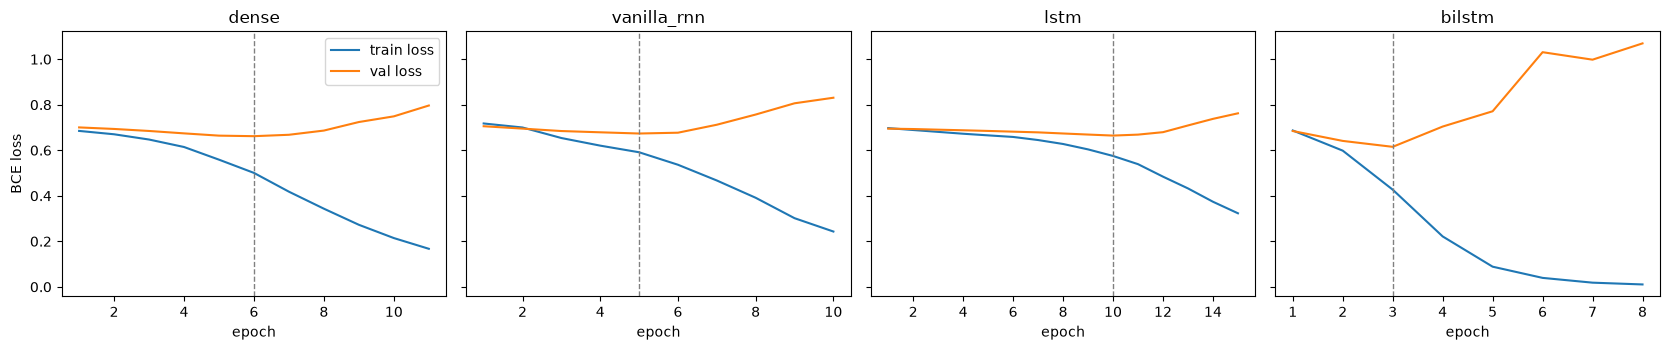

In [6]:
# Curvas de entrenamiento (semilla 42)
fig, ax = plt.subplots(1, len(ALL_MODEL_NAMES), figsize=(4.2*len(ALL_MODEL_NAMES), 3.6), sharey=True)
for a, name in zip(ax, ALL_MODEL_NAMES):
    h = pd.DataFrame(runs[name][0]["history"])
    a.plot(h.epoch, h.train_loss, label="train loss"); a.plot(h.epoch, h.val_loss, label="val loss")
    a.axvline(runs[name][0]["best_epoch"], ls="--", c="gray", lw=1)
    a.set_title(name); a.set_xlabel("epoch")
ax[0].set_ylabel("BCE loss"); ax[0].legend(); plt.tight_layout()
plt.savefig(FIG_DIR/"nn_training_curves.png", dpi=200); plt.show()

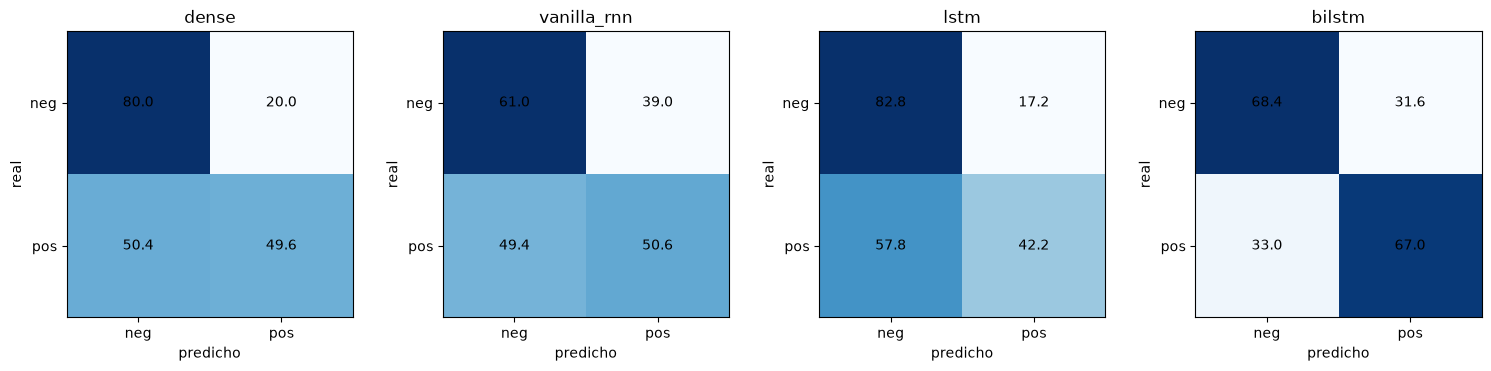

In [7]:
# Matrices de confusión (promedio de semillas)
fig, ax = plt.subplots(1, len(ALL_MODEL_NAMES), figsize=(3.8*len(ALL_MODEL_NAMES), 3.6))
for a, name in zip(ax, ALL_MODEL_NAMES):
    cm = np.array(final[name]["confusion_matrix"])
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): a.text(j, i, f"{cm[i,j]:.1f}", ha="center", va="center")
    a.set_xticks([0,1], ["neg","pos"]); a.set_yticks([0,1], ["neg","pos"])
    a.set_title(name); a.set_xlabel("predicho"); a.set_ylabel("real")
plt.tight_layout(); plt.savefig(FIG_DIR/"nn_confusion_matrices.png", dpi=200); plt.show()

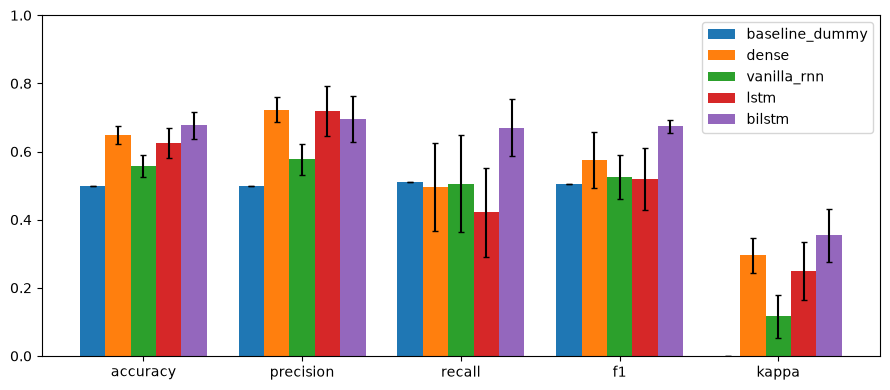

In [8]:
# Comparación de métricas con barras de error (baseline sin error)
mets = ["accuracy","precision","recall","f1","kappa"]
names = ["baseline_dummy"] + ALL_MODEL_NAMES
data = {n: json.loads((METRICS_DIR/f"{n}.json").read_text()) for n in names}
x = np.arange(len(mets)); w = 0.8/len(names)
fig, ax = plt.subplots(figsize=(9, 4))
for i, n in enumerate(names):
    ax.bar(x + (i-(len(names)-1)/2)*w, [data[n][m] for m in mets], w, label=n,
           yerr=[data[n].get("std", {}).get(m, 0) for m in mets], capsize=2)
ax.set_xticks(x, mets); ax.set_ylim(0, 1); ax.legend(); plt.tight_layout()
plt.savefig(FIG_DIR/"nn_metrics_comparison.png", dpi=200); plt.show()

## 6. ¿ayuda conservar las stopwords?
El pipeline del equipo elimina stopwords, pero las RNN/LSTM aprovechan el orden y los conectores. Se reentrenan con `text_mode="full"` y los mismos hiperparámetros.

In [9]:
ftr, fy_tr, fte, fy_te = load_tokens("full")
for name in ["vanilla_rnn", "lstm", "bilstm"]:
    p = final[name]["params"]
    final_runs(name, ftr, fy_tr, fte, fy_te, p, save_name=f"{name}_full")

[2026-11-22 16:22:00] [vanilla_rnn_full] seed=777 best_epoch=6 test_acc=0.5300 f1=0.5392 kappa=0.0600 (4.1s)
[2026-11-22 16:22:02] [vanilla_rnn_full] seed=778 best_epoch=1 test_acc=0.5200 f1=0.2615 kappa=0.0400 (2.3s)
[2026-11-22 16:22:05] [vanilla_rnn_full] seed=779 best_epoch=3 test_acc=0.5250 f1=0.6058 kappa=0.0500 (2.9s)
[2026-11-22 16:22:08] [vanilla_rnn_full] seed=780 best_epoch=4 test_acc=0.5700 f1=0.5700 kappa=0.1400 (3.5s)
[2026-11-22 16:22:11] [vanilla_rnn_full] seed=781 best_epoch=2 test_acc=0.5200 f1=0.4353 kappa=0.0400 (2.5s)
[2026-11-22 16:22:11] [vanilla_rnn_full] MEDIA 5 semillas: accuracy=0.5330±0.0189 precision=0.5424±0.0216 recall=0.4780±0.1917 f1=0.4824±0.1242 kappa=0.0660±0.0377
[2026-11-22 16:22:15] [lstm_full] seed=777 best_epoch=11 test_acc=0.5900 f1=0.4605 kappa=0.1800 (4.0s)
[2026-11-22 16:22:23] [lstm_full] seed=778 best_epoch=15 test_acc=0.6450 f1=0.6570 kappa=0.2900 (7.7s)
[2026-11-22 16:22:34] [lstm_full] seed=779 best_epoch=13 test_acc=0.6300 f1=0.6408 ka